In [18]:
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn import tree

warnings.filterwarnings('ignore')

In [19]:
df = pd.read_csv("13-car_evaluation.csv")

In [20]:
df.head()

,vhigh,vhigh.1,2,2.1,small,low,unacc
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc


In [21]:
df_columns = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]

df.columns = df_columns

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1727 non-null   object
 1   maint     1727 non-null   object
 2   doors     1727 non-null   object
 3   persons   1727 non-null   object
 4   lug_boot  1727 non-null   object
 5   safety    1727 non-null   object
 6   class     1727 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [23]:
for col in df.columns:
    print(df[col].value_counts(), "\n", "-"*30)

buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64 
 ------------------------------
maint
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64 
 ------------------------------
doors
3        432
4        432
5more    432
2        431
Name: count, dtype: int64 
 ------------------------------
persons
4       576
more    576
2       575
Name: count, dtype: int64 
 ------------------------------
lug_boot
med      576
big      576
small    575
Name: count, dtype: int64 
 ------------------------------
safety
med     576
high    576
low     575
Name: count, dtype: int64 
 ------------------------------
class
unacc    1209
acc       384
good       69
vgood      65
Name: count, dtype: int64 
 ------------------------------


In [24]:
# class -> target variable | doors, persons -> numeric variable | rest -> categorical

In [25]:
df["doors"].unique()

array(['2', '3', '4', '5more'], dtype=object)

In [26]:
df["doors"] = df["doors"].replace('5more', 5)
df["doors"] = df["doors"].astype(int)

In [27]:
df["persons"].unique()

array(['2', '4', 'more'], dtype=object)

In [28]:
df["persons"] = df["persons"].replace('more', 5)
df["persons"] = df["persons"].astype(int)

In [29]:
X = df.drop("class", axis=1)
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=15)

In [30]:
ordinal = OrdinalEncoder()

categorical_cols = ["buying", "maint", "lug_boot", "safety"]
numerical_cols = ["doors", "persons"]

ordinal_encoder = OrdinalEncoder(categories = [
    ["low", "med", "high", "vhigh"], # buying
    ["low", "med", "high", "vhigh"], # maint
    ["small", "med", "big"], # lug_boot
    ["low", "med", "high"] # safety
])

pipeline = Pipeline([ # encoding yapilan columnda yapilmayacak hucreler var ise onlari drop edebilir oyuzden passthrough yapmaliyiz.
    ("preprocessor" , ColumnTransformer(transformers = [("transformation_name", ordinal_encoder, categorical_cols)], remainder = "passthrough")),
    ("tree_model", DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=0))
])                  

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, y_pred))
print("-"*60)
print("Classification Report: \n", classification_report(y_test, y_pred))
print("-"*60)
print("Confusion Matix: \n", confusion_matrix(y_test, y_pred))

Accuracy Score:  0.7861271676300579
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

         acc       0.54      0.51      0.53       121
        good       0.00      0.00      0.00        21
       unacc       0.85      0.97      0.91       356
       vgood       0.00      0.00      0.00        21

    accuracy                           0.79       519
   macro avg       0.35      0.37      0.36       519
weighted avg       0.71      0.79      0.75       519

------------------------------------------------------------
Confusion Matix: 
 [[ 62   0  59   0]
 [ 21   0   0   0]
 [ 10   0 346   0]
 [ 21   0   0   0]]


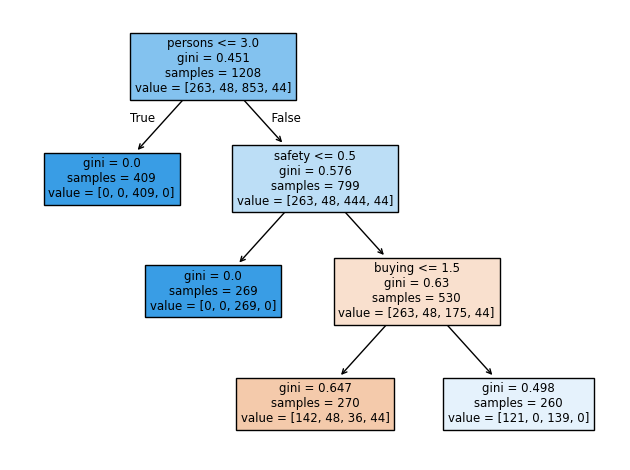

In [31]:
feature_cols = categorical_cols + numerical_cols

tree.plot_tree(pipeline.named_steps["tree_model"], filled=True, feature_names=feature_cols)
plt.tight_layout()
plt.show()

In [32]:
#hyperParameter Tuning

In [33]:
params = ({
    "tree_model__criterion" : ["gini", "entropy", "log_loss"],
    "tree_model__splitter" : ["best", "random"],
    "tree_model__max_depth" : [3, 5, 7, 9, 11, None],
    "tree_model__max_features" : ["sqrt", "log2", None]
})

In [34]:
grid = GridSearchCV(
    pipeline,
    param_grid=params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)
y_pred1 = grid.predict(X_test)

print("Grid Parameters: \n", grid.best_params_)
print("-"*60)
print("Grid Best Score: ", grid.best_score_)
print("-"*60)
print("Accuracy Score: ", accuracy_score(y_test, y_pred1))
print("-"*60)
print("Classifier Report: \n", classification_report(y_test, y_pred1))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred1))

Grid Parameters: 
 {'tree_model__criterion': 'entropy', 'tree_model__max_depth': None, 'tree_model__max_features': None, 'tree_model__splitter': 'best'}
------------------------------------------------------------
Grid Best Score:  0.9693769075134597
------------------------------------------------------------
Accuracy Score:  0.9730250481695568
------------------------------------------------------------
Classifier Report: 
               precision    recall  f1-score   support

         acc       0.91      0.98      0.94       121
        good       1.00      0.86      0.92        21
       unacc       1.00      0.97      0.99       356
       vgood       0.95      1.00      0.98        21

    accuracy                           0.97       519
   macro avg       0.97      0.95      0.96       519
weighted avg       0.97      0.97      0.97       519

------------------------------------------------------------
Confusion Matrix: 
 [[119   0   1   1]
 [  3  18   0   0]
 [  9   0 347   

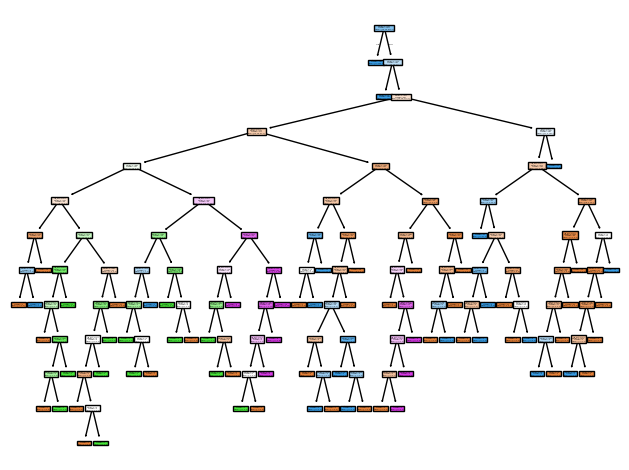

In [107]:
best_pipeline = grid.best_estimator_
best_tree = best_pipeline.named_steps["tree_model"]

tree.plot_tree(best_tree, filled=True, feature_names=feature_cols)
plt.tight_layout()
plt.show()

In [108]:
############################################################################################################################################
############################################################################################################################################

In [109]:
df_new = pd.read_csv("11-iris.csv")

In [110]:
df_new.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [111]:
X = df_new.drop(["Id", "Species"], axis=1)
y = df_new["Species"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=15)

In [115]:
pipeline1 = Pipeline ([
    ("tree", DecisionTreeClassifier(max_depth=3))
])

pipeline1.fit(X_train, y_train)
y_pred2 = pipeline1.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, y_pred2))
print("-"*60)
print("Classification Report: \n", classification_report(y_test, y_pred2))
print("-"*60)
print("Confusion Matix: \n", confusion_matrix(y_test, y_pred2))

Accuracy Score:  0.9736842105263158
------------------------------------------------------------
Classification Report: 
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        12
Iris-versicolor       0.93      1.00      0.97        14
 Iris-virginica       1.00      0.92      0.96        12

       accuracy                           0.97        38
      macro avg       0.98      0.97      0.97        38
   weighted avg       0.98      0.97      0.97        38

------------------------------------------------------------
Confusion Matix: 
 [[12  0  0]
 [ 0 14  0]
 [ 0  1 11]]


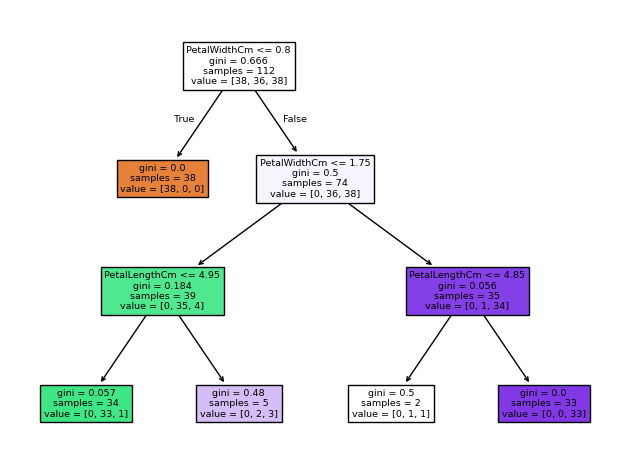

In [116]:
tree.plot_tree(pipeline1.named_steps["tree"], filled=True, feature_names=X_train.columns)
plt.tight_layout()
plt.show()